<a href="https://colab.research.google.com/github/AgentForgeWorkshop/Tutorials/blob/main/Tutorial1_frameworks/01b_workflows_vs_agents.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 1B: LLM call, workflow, agentic workflow, or agent?

**AgentForge Workshop · Tutorial 1, notebook B of 2 · about 25 minutes**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AgentForgeWorkshop/Tutorials/blob/main/Tutorial1_frameworks/01b_workflows_vs_agents.ipynb)

The slides asked one question of every system: **who decides the next step: you, your code,
or the LLM?** Here you build the same task four ways and measure the difference.

> **Task:** "Send me a digest of this week's new arXiv papers on my topic."

| Step | Level | Who decides | Built with | Min |
|---|---|---|---|---|
| 0 | Setup | | | 3 |
| 1 | LLM call | You | a chat model | 2 |
| 2 | LLM workflow | Your code | LangGraph | 5 |
| 3 | Agentic workflow, with an output guardrail | Your code, with the LLM inside one step | LangGraph | 7 |
| 4 | Agent, with tool guardrails and your approval | The LLM | LangChain | 6 |
| 5 | Compare the four | | pandas | 2 |

Notebook A showed what an agent is. Here, the agent is only one of four options, and often
not the best one.

---
## Step 0: Setup

Run the three cells below. The third one holds helpers from notebook A (`search_arxiv`,
`show_trace`, `draw`) plus a `track` helper that counts LLM calls, tokens and seconds for each
run. You do not need to read it.

In [1]:
%pip install -q "langchain==1.4.2" "langchain-google-genai==4.4.0" "langchain-openai==1.6.2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.7/163.7 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.6/81.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.9/267.9 kB 12.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


In [2]:
import getpass
import os

from langchain.chat_models import init_chat_model


def get_key(name: str) -> str:
    """Read an API key from Colab's Secrets panel, or ask for it if there is none."""
    try:
        from google.colab import userdata

        return userdata.get(name)
    except Exception:  # not in Colab, or that secret is not set
        return os.environ.get(name) or getpass.getpass(f"{name}: ")


PROVIDER = "openrouter"  # <-- "openrouter" or "google"

if PROVIDER == "openrouter":
    MODEL_NAME = "openai:deepseek/deepseek-v4.1-flash"
    model = init_chat_model(
        MODEL_NAME,
        temperature=0,
        base_url="https://openrouter.ai/api/v1",
        api_key=get_key("OPENROUTER_API_KEY"),
    )
elif PROVIDER == "google":
    os.environ["GOOGLE_API_KEY"] = get_key("GOOGLE_API_KEY")
    MODEL_NAME = "google_genai:gemini-3.5-flash"
    model = init_chat_model(MODEL_NAME, temperature=0)

TOPIC = "machine learning interatomic potentials for catalysis"  # <-- change me
# Deliberately far too specific: an AND of all these words finds nothing on arXiv.
NARROW = "graphene oxide interlayer humidity stability perovskite tandem solar cell machine learning"

print("Model ready:", MODEL_NAME)

Model ready: openai:deepseek/deepseek-v4.1-flash


In [3]:
# @title Helpers from notebook A, plus run tracking (just run this cell)
import re
import textwrap
import time
import urllib.parse
import urllib.request
import xml.etree.ElementTree as ET
from contextlib import contextmanager
from contextvars import ContextVar
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display
from langchain_core.callbacks import BaseCallbackHandler
from langchain_core.messages import HumanMessage
from langchain_core.tracers.context import register_configure_hook

ARXIV_API = "https://export.arxiv.org/api/query"
ATOM = {"atom": "http://www.w3.org/2005/Atom"}
STOPWORDS = {"a", "an", "and", "are", "as", "at", "based", "by", "for", "from", "in",
             "into", "is", "of", "on", "or", "the", "to", "use", "using", "via", "with"}


def build_arxiv_query(topic: str) -> str:
    """Translate a plain-English topic into arXiv's query language (AND of the words)."""
    words = re.findall(r"[A-Za-z0-9][\w'-]*", topic)
    terms = [w for w in words if w.lower() not in STOPWORDS]
    return " AND ".join(f"all:{w}" for w in terms) or f"all:{topic}"


def search_arxiv(query: str, max_results: int = 5) -> str:
    """Search arXiv for recent papers and return their titles, authors, links and abstracts.

    Args:
        query: Search terms, e.g. 'graph neural network catalyst screening'.
        max_results: How many papers to return (1-10).
    """
    search_query = build_arxiv_query(query)
    params = urllib.parse.urlencode({
        "search_query": search_query, "start": 0, "max_results": min(max_results, 10),
        "sortBy": "submittedDate", "sortOrder": "descending",
    })
    with urllib.request.urlopen(f"{ARXIV_API}?{params}", timeout=30) as response:
        feed = ET.fromstring(response.read())
    papers = []
    for entry in feed.findall("atom:entry", ATOM):
        title = " ".join(entry.findtext("atom:title", "", ATOM).split())
        abstract = " ".join(entry.findtext("atom:summary", "", ATOM).split())
        authors = [a.findtext("atom:name", "", ATOM) for a in entry.findall("atom:author", ATOM)]
        papers.append(
            f"Title: {title}\n"
            f"Authors: {', '.join(authors[:3])}{' et al.' if len(authors) > 3 else ''}\n"
            f"Published: {entry.findtext('atom:published', '', ATOM)[:10]}\n"
            f"Link: {entry.findtext('atom:id', '', ATOM)}\n"
            f"Abstract: {textwrap.shorten(abstract, 1000, placeholder=' ...')}"
        )
    if not papers:
        return (f"No papers found for '{query}' (sent to arXiv as: {search_query}). "
                "Try fewer or broader search terms.")
    return "\n\n---\n\n".join(papers)


def count_papers(result: str) -> int:
    return 0 if result.startswith("No papers found") else result.count("Title:")


def arxiv_ids(text: str) -> list:
    """All arXiv ids (like 2610.02013) mentioned in a text."""
    return sorted(set(re.findall(r"\b(\d{4}\.\d{4,5})(?:v\d+)?\b", text or "")))


def show_trace(result, width=200):
    """Print an agent run as Thought / Action / Observation."""
    for message in result["messages"]:
        kind = type(message).__name__
        text = (message.text or "").strip()
        if kind == "HumanMessage":
            print(f"You:         {textwrap.shorten(text, width)}")
        elif kind == "ToolMessage":
            found = count_papers(text) if text.startswith(("Title:", "No papers")) else None
            print(f"Observation: {f'{found} papers' if found is not None else textwrap.shorten(text, 100)}")
        elif message.tool_calls:
            if text:
                print(f"Thought:     {textwrap.shorten(text, width)}")
            for call in message.tool_calls:
                args = {k: textwrap.shorten(str(v), 60) for k, v in call["args"].items()}
                print(f"Action:      {call['name']}({args})")
        elif text:
            print(f"Answer:      {textwrap.shorten(text, width)}")


def draw(graph):
    """Draw a LangGraph graph (falls back to text if the drawing service is unreachable)."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())


class _Counter(BaseCallbackHandler):
    """Counts every LLM call made inside a `track` block, and the tokens it used."""

    def __init__(self):
        self.llm_calls, self.tokens = 0, 0

    def on_llm_end(self, response, **kwargs):
        self.llm_calls += 1
        for generation in response.generations:
            for g in generation:
                usage = getattr(getattr(g, "message", None), "usage_metadata", None) or {}
                self.tokens += usage.get("total_tokens", 0)


_counter = ContextVar("workshop_counter", default=None)
register_configure_hook(_counter, inheritable=True)
RUNS = []  # one row per tracked run, for the comparison in Step 5


@contextmanager
def track(level: str, topic: str):
    """Measure everything inside the `with` block: LLM calls, tokens, seconds."""
    counter, start = _Counter(), time.time()
    row = {"level": level, "topic": topic}
    token = _counter.set(counter)
    try:
        yield row
    finally:
        _counter.reset(token)
        row.update(llm_calls=counter.llm_calls, tokens=counter.tokens,
                   seconds=round(time.time() - start, 1))
        RUNS.append(row)
        calls = f"{counter.llm_calls} LLM call{'' if counter.llm_calls == 1 else 's'}"
        print(f"\n✓ {level} ({topic}): {calls}, {counter.tokens:,} tokens, "
              f"{row['seconds']} s")


print("Helpers ready.")

Helpers ready.


---
## Step 1: LLM call. **You** decide.

One prompt, one answer. We fetch one paper for you and ask for a summary.

In [4]:
one_paper = search_arxiv(TOPIC, max_results=1)

with track("1) LLM call", "normal topic") as run:
    reply = model.invoke(f"Summarise this paper for a colleague in 3 sentences, then give its link:\n\n{one_paper}")
    run["papers"] = arxiv_ids(reply.text)

print(reply.text)


✓ 1) LLM call (normal topic): 1 LLM call, 1,441 tokens, 8.8 s
This paper benchmarks whether universal machine-learning interatomic potentials (uMLIPs) can capture small polarons in transition-metal oxides, using a geometric descriptor based on TM–O bond-length expansion (Z-score) to identify H-induced polaronic distortions. It finds that uMLIP behavior ranges from delocalized electrons to metastable small polarons, strongly depending on training data and treatment of electronic correlations, with missing Hubbard U corrections for certain TM cations leading to delocalization relative to DFT+U. Although some uMLIPs reproduce polaron hopping barriers, the overall result is that uMLIPs are not uniformly reliable for small polarons and require careful validation/training choices.

Link: http://arxiv.org/abs/2610.17352v1


Good at what it does. But **you** chose the paper, **you** would repeat this for every
paper, and **you** would write and send the digest. Nothing here can search, retry, or act.

---
## Step 2: LLM workflow. **Your code** decides.

Now the steps are fixed in code: **search → summarise → write the digest → save**. Two of
those steps call the LLM, each working on the previous one's output: the *prompt chaining*
pattern from the slides.

We build it with **LangGraph**: each step is a Python function (a *node*) that reads a shared
`state` dict and returns the keys it changed. Edges say what runs next.

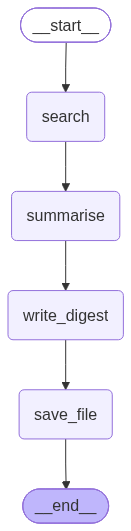

In [5]:
from typing import TypedDict

from langgraph.graph import END, START, StateGraph


class DigestState(TypedDict, total=False):
    topic: str      # what the scientist asked for
    query: str      # what we actually send to arXiv
    papers: str     # raw search results
    n_found: int
    attempts: int
    notes: str      # one bullet per paper
    digest: str     # the final email text
    bad_ids: list   # Step 3: citations that failed the check
    fixes: int      # Step 3: how many times the draft was sent back


def search(state: DigestState) -> dict:                       # code, no LLM
    query = state.get("query") or state["topic"]
    papers = search_arxiv(query, max_results=5)
    print(f"  search({query!r}) -> {count_papers(papers)} papers")
    return {"query": query, "papers": papers, "n_found": count_papers(papers),
            "attempts": state.get("attempts", 0) + 1}


def summarise(state: DigestState) -> dict:                    # LLM
    notes = model.invoke(
        "For each paper below write one bullet: the title, the link, and the key finding "
        "in one sentence. Use only the text below.\n\n" + state["papers"]
    ).text
    return {"notes": notes}


def write_digest(state: DigestState) -> dict:                 # LLM
    digest = model.invoke(
        f"Turn these notes into a short weekly digest email for my lab about "
        f"'{state['topic']}'. Start with a subject line. Keep every link.\n\n{state['notes']}"
    ).text
    return {"digest": digest}


def save_file(state: DigestState) -> dict:                    # code, no LLM
    Path("digest.md").write_text(state["digest"], encoding="utf-8")
    return {}


builder = StateGraph(DigestState)
for step in (search, summarise, write_digest, save_file):
    builder.add_node(step)
builder.add_edge(START, "search")
builder.add_edge("search", "summarise")
builder.add_edge("summarise", "write_digest")
builder.add_edge("write_digest", "save_file")
builder.add_edge("save_file", END)

workflow = builder.compile()
draw(workflow)

In [6]:
with track("2) LLM workflow", "normal topic") as run:
    out = workflow.invoke({"topic": TOPIC})
    run["papers"] = arxiv_ids(out["digest"])

display(Markdown(out["digest"]))

  search('machine learning interatomic potentials for catalysis') -> 5 papers

✓ 2) LLM workflow (normal topic): 2 LLM calls, 6,267 tokens, 27.2 s


**Subject:** Weekly MLIP for Catalysis Digest — Polarons, BranchIP, HetCat26, SoLiD26, Graphene Defects

Hi all,

Here’s this week’s short digest on machine learning interatomic potentials for catalysis.

1. **Can Universal Machine-Learning Interatomic Potentials Capture Small Polarons? A Geometry-Based Benchmark in Transition-Metal Oxides** — http://arxiv.org/abs/2610.17352v1  
   Uses a TM–O bond-length expansion Z-score descriptor to identify polaronic distortions. uMLIPs show varied electron localization, from delocalized states to metastable small polarons, depending on training data and electronic-correlation treatment; missing Hubbard U for specific TM cations leads to delocalization, unlike DFT+U.

2. **BranchIP: Learning Adaptive Equivariant Computation for Interatomic Potentials** — http://arxiv.org/abs/2610.02013v1  
   A single-model framework for learned adaptive tensor product computation with a distillation loss. It speeds up MLIPs by up to 2.4× and reduces memory by up to 2.6× while maintaining physical fidelity, and reveals which interactions need deeper computation.

3. **Assessing the Transferability of General-Purpose Machine Learning Interatomic Potentials for Heterogeneous Catalysis with HetCat26** — http://arxiv.org/abs/2609.30621v1  
   Fifteen foundation models evaluated on HetCat26. General materials benchmark performance is only weakly predictive of HetCat26 performance, so transferability to heterogeneous catalysis cannot be inferred from those benchmarks. Surface energetics and reaction barriers are described well; adsorption shows larger errors.

4. **SoLiD26: A First Principles Solid-Liquid Interface Dataset for Machine-learned Interatomic Potentials** — http://arxiv.org/abs/2609.28013v1  
   Presents SoLiD26, a curated solid–liquid interface dataset with 15.4 million first-principles atomic structures, up to 576 atoms, and 15 chemical elements for training and evaluating MLIPs.

5. **Breaking Water at Graphene Defects** — http://arxiv.org/abs/2609.11602v1  
   Using state-of-the-art MLIPs, solvation qualitatively changes the reaction mechanism at a graphene single vacancy. The solvated SV splits water through competing basic (SV-H + OH⁻(aq)) and acidic (SV-OH + H₃O⁺(aq)) pathways, producing distinct chemisorbed intermediates and enhancing graphene–water adsorption.

Best,  
[Your name]

A straight line, the same every run: easy to test, easy to reproduce. Now give it the topic
that is too specific:

In [7]:
with track("2) LLM workflow", "narrow topic") as run:
    out = workflow.invoke({"topic": NARROW})
    run["papers"] = arxiv_ids(out["digest"])

display(Markdown(out["digest"]))

  search('graphene oxide interlayer humidity stability perovskite tandem solar cell machine learning') -> 0 papers

✓ 2) LLM workflow (narrow topic): 2 LLM calls, 1,986 tokens, 16.4 s


Subject: Weekly Digest — No exact arXiv hits for GO interlayer / humidity-stable perovskite tandem / ML

Hi lab,

No papers found this week for:
“graphene oxide interlayer humidity stability perovskite tandem solar cell machine learning”

arXiv query used:
all:graphene AND all:oxide AND all:interlayer AND all:humidity AND all:stability AND all:perovskite AND all:tandem AND all:solar AND all:cell AND all:machine AND all:learning

Suggestion: try fewer or broader search terms.

Links: none this week.

Best,
[Your name]

The search found nothing, and the workflow carried on anyway: it summarised nothing and
wrote an email about nothing (or, worse, about papers the model made up). As the slide said:
**same steps every run, even if the search finds nothing.** The code had no way to react.

---
## Step 3: Agentic workflow. **Your code** decides the steps, **the LLM** decides inside one.

Keep every step from Step 2, and add one decision point after the search:

* papers found → carry on as before;
* nothing found → **the LLM rewrites the query**, and we search again, at most 3 times;
* still nothing → say so honestly.

And add one **output guardrail** before saving (slides: "Guardrails"). `check_citations` is
plain code: every arXiv paper in the digest must be one the search returned. If not, the draft
goes back to the LLM with feedback, at most 2 times; after that it is saved with a
"needs human review" banner. It is the same rule as the HPLC sample answer in the slides.

Both loops are small, bounded, and sit exactly where they are needed. Everything else stays
plain, predictable code.

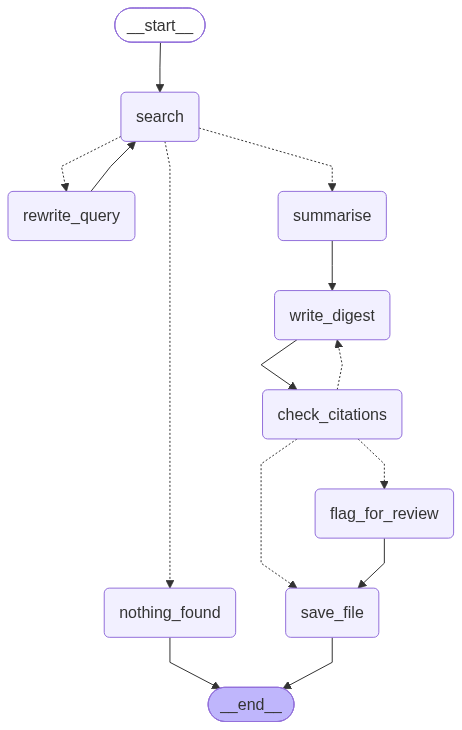

In [8]:
def rewrite_query(state: DigestState) -> dict:                # LLM: the judgment step
    new_query = model.invoke(
        f"An arXiv search for '{state['query']}' found nothing. The scientist's topic is "
        f"'{state['topic']}'. Reply with ONE broader search query of at most 4 words, "
        "and nothing else."
    ).text.strip().strip("\"'")
    print(f"  LLM rewrote the query -> {new_query!r}")
    return {"query": new_query}


def nothing_found(state: DigestState) -> dict:                # code
    return {"digest": f"No new papers found on '{state['topic']}' "
                      f"after {state['attempts']} searches."}


def after_search(state: DigestState) -> str:                  # code: the routing rule
    if state["n_found"] > 0:
        return "summarise"
    if state["attempts"] < 3:
        return "rewrite_query"
    return "nothing_found"


def write_digest_with_feedback(state: DigestState) -> dict:   # LLM, told what failed last time
    notes = state["notes"]
    if state.get("bad_ids"):
        notes += (f"\n\nYour previous draft cited {state['bad_ids']}, which are not in these "
                  "notes. Rewrite the digest without them.")
    return write_digest({**state, "notes": notes})


def check_citations(state: DigestState) -> dict:              # 🛡️ output guardrail (code)
    bad = sorted(set(arxiv_ids(state["digest"])) - set(arxiv_ids(state["papers"])))
    if bad:
        print(f"  🛡️ check_citations: {bad} are not in the search results")
    else:
        print("  🛡️ check_citations: every cited paper came from the search")
    return {"bad_ids": bad, "fixes": state.get("fixes", 0) + (1 if bad else 0)}


def after_check(state: DigestState) -> str:                   # 🛡️ what happens when it trips
    if not state["bad_ids"]:
        return "save_file"
    if state["fixes"] <= 2:
        return "write_digest"                                 # feedback to the LLM
    return "flag_for_review"                                  # then a human


def flag_for_review(state: DigestState) -> dict:              # code
    return {"digest": f"⚠️ NEEDS HUMAN REVIEW: {state['bad_ids']} are not in the search "
                      f"results.\n\n{state['digest']}"}


builder = StateGraph(DigestState)
for step in (search, rewrite_query, summarise, check_citations, save_file,
             nothing_found, flag_for_review):
    builder.add_node(step)
builder.add_node("write_digest", write_digest_with_feedback)
builder.add_edge(START, "search")
builder.add_conditional_edges("search", after_search,
                              ["summarise", "rewrite_query", "nothing_found"])
builder.add_edge("rewrite_query", "search")                   # loop 1: retry the search
builder.add_edge("summarise", "write_digest")
builder.add_edge("write_digest", "check_citations")
builder.add_conditional_edges("check_citations", after_check,
                              ["save_file", "write_digest", "flag_for_review"])  # loop 2
builder.add_edge("flag_for_review", "save_file")
builder.add_edge("save_file", END)
builder.add_edge("nothing_found", END)

agentic_workflow = builder.compile()
draw(agentic_workflow)

In [9]:
with track("3) Agentic workflow", "narrow topic") as run:
    out = agentic_workflow.invoke({"topic": NARROW})
    run["papers"] = arxiv_ids(out["digest"])

display(Markdown(out["digest"]))

  search('graphene oxide interlayer humidity stability perovskite tandem solar cell machine learning') -> 0 papers
  LLM rewrote the query -> 'perovskite tandem solar cells'
  search('perovskite tandem solar cells') -> 5 papers
  🛡️ check_citations: every cited paper came from the search

✓ 3) Agentic workflow (narrow topic): 3 LLM calls, 6,399 tokens, 86.6 s


**Subject:** Lab Weekly Digest — Perovskite Stability, Tandem Losses, Defect Fingerprinting & ML Imaging

Hi all,

Here’s this week’s short digest of relevant perovskite/tandem/stability/ML papers. Several connect directly to our interests in interlayer/humidity stability, tandem device loss analysis, and ML-supported characterization.

- **High-Throughput Imaging of Degradation-Inducing Microscopic Impurities in Perovskite Solar Cells** — http://arxiv.org/abs/2609.35510v1  
  Photo-stress experiments show degradation initiates at impurity–perovskite interfaces, and the authors develop a rapid, non-invasive, high-throughput framework using high-resolution reflected-light microscopy plus machine-learning-supported image analysis.

- **Divergent Solid-state Conversion Pathways in Evaporated All-perovskite Tandem Solar Cells** — http://arxiv.org/abs/2609.20326v1  
  Time-sliced ex situ analysis reveals different solid-state conversion mechanisms in sequentially evaporated WBG and NBG precursor stacks, including FA-containing species penetration and Br/I redistribution in WBG stacks, and early Pb-rich perovskite formation in NBG stacks.

- **Terahertz Time-Domain Spectroscopy as a Universal Defect Fingerprinting Tool for Organic Halide Perovskite Solar Cells** — http://arxiv.org/abs/2607.15538v1  
  This short review argues THz-TDS (0.3–3.0 THz) can non-contactly identify and quantify specific defect species in device-relevant thin films, capturing intrinsic phonon modes and GB-localized molecular defect vibrations across four OHP compositions.

- **Characterizing Fill Factor Limitations in Perovskite-Silicon Tandem Solar Cells** — http://arxiv.org/abs/2604.24098v1  
  Presents a methodology for FF-loss mechanisms in perovskite-Si monolithic tandems, including series-resistance-related loss characterized by electroluminescence and a photoshunt-related loss factor linked to moderate charge-transport-layer mobility.

- **Understanding halide segregation in metal halide perovskites through defect thermodynamics** — http://arxiv.org/abs/2603.07829v1  
  First-principles slab calculations show bromide preferentially occupies surface sites over bulk sites and that halide segregation is thermodynamically more favorable in MAPb(Br\(_x\)I\(_{1-x}\))\(_3\) than in FA\(_{0.8}\)Cs\(_{0.2}\)Pb(Br\(_x\)I\(_{1-x}\))\(_3\).

Best,  
[Your name]

In [10]:
# On the normal topic the search loop never runs; the citation check still does.
with track("3) Agentic workflow", "normal topic") as run:
    out = agentic_workflow.invoke({"topic": TOPIC})
    run["papers"] = arxiv_ids(out["digest"])

# A good model usually passes the check, so here is what a trip looks like:
check_citations({"digest": "See arXiv:2401.99999 for details.", "papers": out["papers"]})

  search('machine learning interatomic potentials for catalysis') -> 5 papers
  🛡️ check_citations: every cited paper came from the search

✓ 3) Agentic workflow (normal topic): 2 LLM calls, 6,326 tokens, 31.4 s
  🛡️ check_citations: ['2401.99999'] are not in the search results


{'bad_ids': ['2401.99999'], 'fixes': 1}

This is the shape of most useful research pipelines, and of the HPLC tracker in the slides'
exercises: **fixed outer steps, the LLM looping only where the path cannot be planned
ahead, and guardrails as ordinary steps in the graph.**

---
## Step 4: Agent. **The LLM** decides.

No graph of steps this time. We give the model three tools and a goal, and it chooses which
tools to call, in what order, and when to stop:

* `search_arxiv`;
* `check_seen`: a tiny "database" of papers you have already read (we pretend you read two of
  the papers from Step 2 last week);
* `save_digest`: writes the final email to a file.

You cannot draw guardrails into a path the agent has not chosen yet, so they wrap the loop
instead. Three **tool guardrails**, all code:

* 🛡️ `save_digest` itself only writes new `.md` files inside `digests/`, and never overwrites;
* 🛡️ at most 3 searches per run (middleware);
* 🛡️ **you approve** before anything is saved (middleware): the slides' human in the loop.

In [16]:
SEEN = set(arxiv_ids(search_arxiv(TOPIC, max_results=5))[:2])  # "read last week"
SAVED = []  # every file the agent saved


def check_seen(links: list[str]) -> str:
    """Check which papers the scientist has already read.

    Args:
        links: arXiv links or ids of the papers you are considering.
    """
    ids = arxiv_ids(" ".join(links))
    seen = [i for i in ids if i in SEEN]
    new = [i for i in ids if i not in SEEN]
    return f"Already read: {seen or 'none'}. Not read yet: {new or 'none'}."


def save_digest(filename: str, content: str) -> str:
    """Save the finished digest email in the digests/ folder.

    Args:
        filename: A new file name ending in .md, e.g. 'digest_mlip.md'.
        content: The full digest in markdown, starting with a subject line.
    """
    path = Path("digests") / filename
    if Path(filename).name != filename or path.suffix != ".md":   # 🛡️ only digests/*.md
        return f"Denied: '{filename}' must be a plain filename inside the digests/ folder and end with .md."
    if path.exists():                                             # 🛡️ never overwrite
        return f"Denied: {path} already exists. Choose a new file name."
    path.parent.mkdir(exist_ok=True)
    path.write_text(content, encoding="utf-8")
    SAVED.append(path)
    return f"Saved {path}"


# The tool refuses a request outside its permission, whoever sends it:
print(save_digest("../thesis/chapter1.md", "oops"))

Denied: '../thesis/chapter1.md' must be a plain filename inside the digests/ folder and end with .md.


In [12]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware, ToolCallLimitMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command

AGENT_PROMPT = (
    "You prepare a weekly digest of new arXiv papers for a scientist. "
    "Use search_arxiv to find papers; if a search finds nothing, try broader terms. "
    "Use check_seen and leave out papers the scientist has already read. "
    "Report only what the tools returned, with links. "
    "When the digest is ready, save it with save_digest."
)

digest_agent = create_agent(
    model,
    tools=[search_arxiv, check_seen, save_digest],
    system_prompt=AGENT_PROMPT,
    middleware=[
        ToolCallLimitMiddleware(tool_name="search_arxiv", run_limit=3),  # 🛡️ max 3 searches
        HumanInTheLoopMiddleware(interrupt_on={"save_digest": True}),     # 🛡️ you approve saving
    ],
    checkpointer=InMemorySaver(),  # remembers where the run paused while it waits for you
)


def run_with_approval(agent, request: str, thread_id: str):
    """Run the agent; whenever it pauses for approval, ask you."""
    config = {"configurable": {"thread_id": thread_id}}
    result = agent.invoke({"messages": [HumanMessage(request)]}, config)
    while "__interrupt__" in result:                   # the agent paused for you
        action = result["__interrupt__"][0].value["action_requests"][0]
        print(f"\n🛡️ The agent wants to run {action['name']} with:\n")
        print(textwrap.shorten(str(action["args"]), 800), "\n")
        if input("Approve? [y/n] ").strip().lower().startswith("y"):
            decision = {"type": "approve"}
        else:
            decision = {"type": "reject", "message": "Not approved. Do not save it."}
        result = agent.invoke(Command(resume={"decisions": [decision]}), config)
    return result


saved_before = len(SAVED)
with track("4) Agent", "normal topic") as run:
    result = run_with_approval(digest_agent, f"Prepare this week's digest on {TOPIC}.", "digest-1")
    run["papers"] = arxiv_ids(SAVED[-1].read_text()) if len(SAVED) > saved_before else []

show_trace(result)


🛡️ The agent wants to run save_digest with:

{'filename': 'digest_mlip_catalysis.md', 'content': '# Weekly Digest: Machine Learning Interatomic Potentials for Catalysis\n\nSubject: MLIPs for Catalysis — Weekly Digest (benchmarks, fine-tuning, and reactive dynamics)\n\nHere are this week\'s picks on machine learning interatomic potentials (MLIPs) for catalysis. Papers you\'ve already read (Breaking Water at Graphene Defects; SoLiD26) have been excluded.\n\n---\n\n## Benchmarks & Transferability\n\n### 1. Assessing the Transferability of General-Purpose Machine-Learning Interatomic Potentials for Heterogeneous Catalysis with HetCat26\n**Authors:** Alexandre Peuch, Giaan Kler-Young, Kaifeng Niu et al.\n**Published:** 2026-09-24\n**Link:** http://arxiv.org/abs/2609.30621v1\n\nIntroduces HetCat26, a benchmark suite for pre-trained [...] 

Approve? [y/n] y

✓ 4) Agent (normal topic): 4 LLM calls, 24,890 tokens, 990.2 s
You:         Prepare this week's digest on machine learning interatomic 

Nobody wrote "check what was already read before saving" or "retry with broader terms" as
code. The model chose it, and it might choose differently next time: re-run the cell and
compare the traces. That flexibility is the point of an agent, and the reason it needs
guardrails around it. *(The seconds for this run include the time you took to approve.)*

---
## Step 5: Compare

Every tracked run went into `RUNS`. Same task, four levels:

In [13]:
WHO_DECIDES = {"1) LLM call": "You", "2) LLM workflow": "Your code",
               "3) Agentic workflow": "Code + LLM in one step", "4) Agent": "The LLM"}

table = pd.DataFrame(RUNS)
table.insert(1, "who decides", table["level"].map(WHO_DECIDES))
table["n_papers"] = table["papers"].map(len)
table.drop(columns="papers").sort_values(["topic", "level"], ignore_index=True)

,level,who decides,topic,llm_calls,tokens,seconds,n_papers
0,2) LLM workflow,Your code,narrow topic,2,1986,16.4,0
1,3) Agentic workflow,Code + LLM in one step,narrow topic,3,6399,86.6,5
2,1) LLM call,You,normal topic,1,1441,8.8,1
3,2) LLM workflow,Your code,normal topic,2,6267,27.2,5
4,3) Agentic workflow,Code + LLM in one step,normal topic,2,6326,31.4,5
5,4) Agent,The LLM,normal topic,4,24890,990.2,12


### What to notice

* **Cost grows with autonomy.** Count the LLM calls and tokens per level. The agent resends
  its whole context at every step.
* **Only a level with an LLM decision coped with the narrow topic.** The plain workflow
  wrote an empty (or invented) digest.
* **Reproducibility falls with autonomy.** The workflow takes the same path every run; the
  agent may not (backup slide "Same task, different paths").
* **Guardrails fit each level differently.** In a workflow they are steps you draw into the
  graph (`check_citations`). Around an agent they are narrow tools and middleware, because
  you cannot know its path in advance.

That is the decision tree from the slides:

> Can one prompt do it? → **LLM call**. Are all the steps known in advance? → **LLM
> workflow**. Does only part of it need run-time judgment? → **agentic workflow**. Otherwise →
> **agent**. *Start with the simplest option. Add autonomy only when it pays off.*

### What about agents that run other agents?

An agent's tool can itself be another agent: a lead agent decides at run time which
specialist agents to call, gives them sub-tasks, and combines their answers. That is a
**multi-agent system**, the topic of **Tutorial 4**.

---
## Your turn (take-home)

Take your design from the slides' exercises (or the HPLC tracker), fill in the table below,
then try building it at the level you chose, starting from the closest graph or agent above.

| | Your answer |
|---|---|
| Trigger / input | |
| Steps | |
| Tools | |
| Where the LLM decides | |
| LLM call, workflow, agentic workflow or agent? Why? | |
| Input guardrail, and what happens when it trips | |
| Tool guardrail, and what happens when it trips | |
| Output guardrail, and what happens when it trips | |

---
*AgentForge Workshop, Tutorial 1B. Questions, fixes and better examples are welcome:
<https://github.com/AgentForgeWorkshop/Tutorials>*